# **Impact of RBI Repo Rate Changes on NBFC Lending Behavior (2018–2024)**

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

# Plot style
plt.rcParams["figure.figsize"] = (12,5)
plt.rcParams["font.size"] = 10

In [ ]:

df = pd.read_csv("/content/Untitled spreadsheet - master sheet.csv")

df.head()


,Company,Ticker,Quarter,Calendar Period,Repo Rate (%),Repo QoQ Chg (bps),Rate Hike,Rate Cut,AUM (Cr),Loan Growth YoY%,GNPA (%),NIM (%),CoF (%),Spread (%),CAR (%)
0,Bajaj Finance,BAJFINANCE,Q1 FY19,Apr-Jun 18,6.25,NaN,NaN,NaN,"97,000",NaN,1.6,10.8,7.8,3.0,22.5
1,Bajaj Finance,BAJFINANCE,Q2 FY19,Jul-Sep 18,6.50,25.0,25.0,0.0,"1,05,000",NaN,1.5,10.9,7.9,3.0,22.2
2,Bajaj Finance,BAJFINANCE,Q3 FY19,Oct-Dec 18,6.50,0.0,0.0,0.0,"1,10,700",NaN,1.6,11.0,8.2,2.8,22.0
3,Bajaj Finance,BAJFINANCE,Q4 FY19,Jan-Mar 19,6.25,-25.0,0.0,25.0,"1,15,888",NaN,1.5,10.9,8.5,2.4,21.8
4,Bajaj Finance,BAJFINANCE,Q1 FY20,Apr-Jun 19,5.75,-50.0,0.0,50.0,"1,23,000",26.8,1.6,10.7,8.3,2.4,22.0


**DATA CLEANING**

In [ ]:
# Missing values
print(df.isnull().sum())

# Sort dataset
df = df.sort_values(by=["Company","Quarter"])

# Reset index
df = df.reset_index(drop=True)

# Dataset info
df.info()


Company                0
Ticker                 0
Quarter                0
Calendar Period        0
Repo Rate (%)          0
Repo QoQ Chg (bps)     5
Rate Hike              5
Rate Cut               5
AUM (Cr)               0
Loan Growth YoY%      20
GNPA (%)               0
NIM (%)                0
CoF (%)                0
Spread (%)             0
CAR (%)                0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Company             120 non-null    object 
 1   Ticker              120 non-null    object 
 2   Quarter             120 non-null    object 
 3   Calendar Period     120 non-null    object 
 4   Repo Rate (%)       120 non-null    float64
 5   Repo QoQ Chg (bps)  115 non-null    float64
 6   Rate Hike           115 non-null    float64
 7   Rate Cut            115 non-null    float64
 8   AUM (Cr)    

In [ ]:
quarter_map = {
    "Jan-Mar": "01",
    "Apr-Jun": "04",
    "Jul-Sep": "07",
    "Oct-Dec": "10"
}

# Extract quarter name
df["Quarter_Name"] = df["Calendar Period"].str[:7]

# Extract year
df["Year"] = "20" + df["Calendar Period"].str[-2:]

# Map month
df["Month"] = df["Quarter_Name"].map(quarter_map)

# Create proper date column
df["Date"] = pd.to_datetime(
    df["Year"] + "-" + df["Month"] + "-01"
)

# Sort chronologically
df = df.sort_values("Date")

**RESEARCH VARIABLES**

**Independent Variable**

**Repo Rate (%) **

The RBI policy interest rate used to control liquidity and inflation.

**Dependent Variables**

**Loan Growth YoY (%)**

Measures credit expansion by NBFCs.

**Cost of Funds (CoF %)**

Average borrowing cost of NBFCs.

**GNPA (%)**

Gross Non-Performing Assets ratio indicating asset quality deterioration.

**NIM (%)**

Net Interest Margin indicating lending profitability.



**VISUAL ANALYSIS**

**RBI REPO RATE TREND**

Purpose

Shows India’s monetary policy cycle:

•	tightening,

•	easing,

•	COVID stimulus,

•	inflation-control hikes.


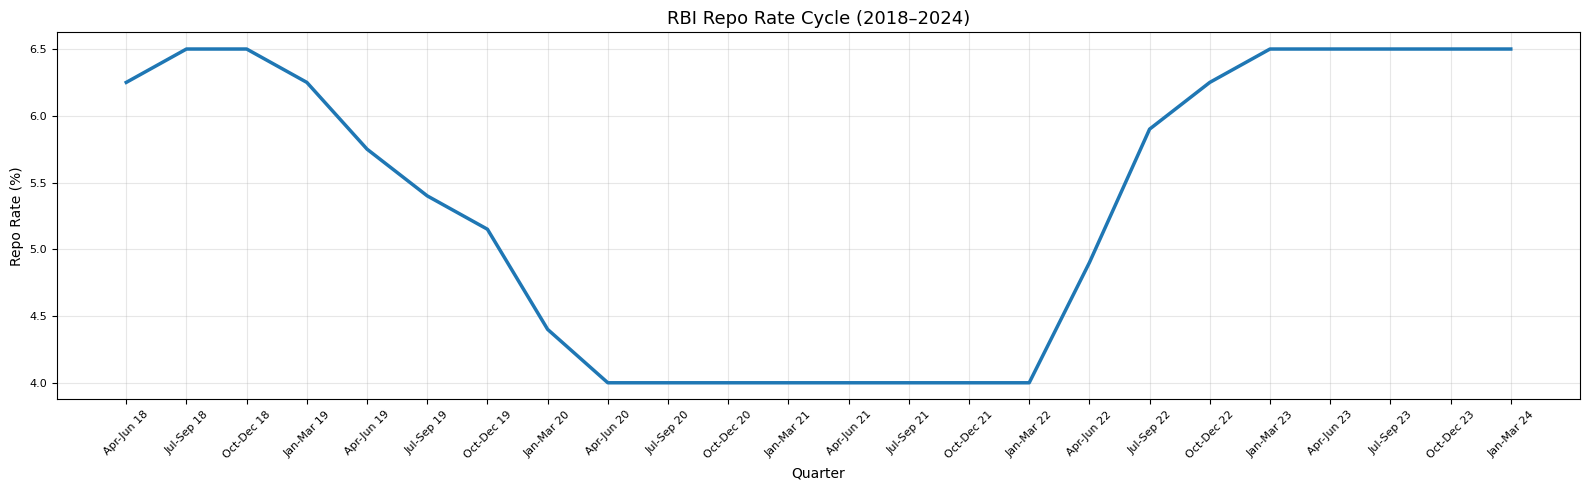

In [ ]:
# ======================================
# RBI REPO RATE TREND
# WITH QUARTERS ON X-AXIS
# ======================================

repo = df.groupby(
    ["Date", "Calendar Period"]
)["Repo Rate (%)"].mean().reset_index()

plt.figure(figsize=(16,5))

plt.plot(
    repo["Calendar Period"],
    repo["Repo Rate (%)"],
    linewidth=2.5
)

plt.title(
    "RBI Repo Rate Cycle (2018–2024)",
    fontsize=13
)

plt.xlabel(
    "Quarter",
    fontsize=10
)

plt.ylabel(
    "Repo Rate (%)",
    fontsize=10
)

plt.xticks(
    rotation=45,
    fontsize=8
)

plt.yticks(
    fontsize=8
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

**Interpretation**

Expected observations:

•	2018 tightening cycle,

•	2019 easing,

•	COVID emergency cuts,

•	aggressive hikes during FY23.    


**RBI Repo Rate vs Average NBFC Cost of Funds**

**Purpose**

Tests monetary transmission.

**Question:** > Do NBFC borrowing costs rise when repo rate rises?


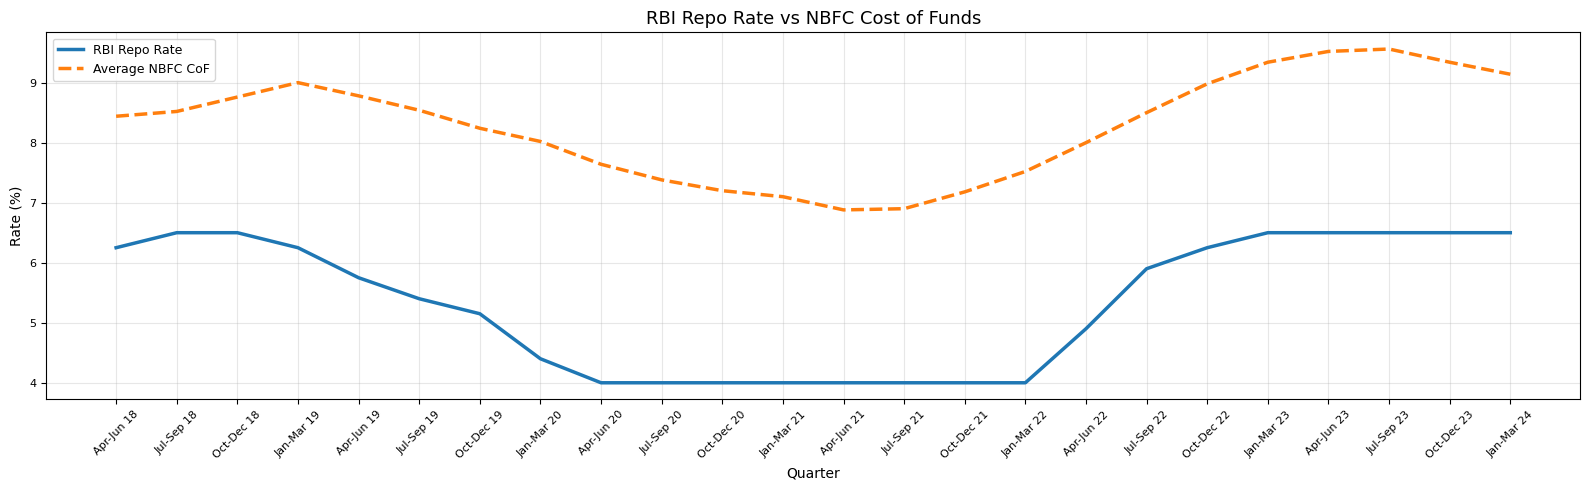

In [ ]:
# ======================================
# RBI REPO RATE vs NBFC CoF
# SORTED QUARTERLY VISUAL
# ======================================

# Group data properly
quarterly = df.groupby(
    ["Date", "Calendar Period"]
).agg({
    "Repo Rate (%)":"mean",
    "CoF (%)":"mean"
}).reset_index()

# Sort chronologically
quarterly = quarterly.sort_values("Date")

# Plot
plt.figure(figsize=(16,5))

plt.plot(
    quarterly["Calendar Period"],
    quarterly["Repo Rate (%)"],
    linewidth=2.5,
    label="RBI Repo Rate"
)

plt.plot(
    quarterly["Calendar Period"],
    quarterly["CoF (%)"],
    linewidth=2.5,
    linestyle="--",
    label="Average NBFC CoF"
)

# Title
plt.title(
    "RBI Repo Rate vs NBFC Cost of Funds",
    fontsize=13
)

# Labels
plt.xlabel(
    "Quarter",
    fontsize=10
)

plt.ylabel(
    "Rate (%)",
    fontsize=10
)

# Axis formatting
plt.xticks(
    rotation=45,
    fontsize=8
)

plt.yticks(
    fontsize=8
)

# Legend
plt.legend(
    fontsize=9
)

# Grid
plt.grid(alpha=0.3)

# Layout fix
plt.tight_layout()

# Show chart
plt.show()

**Interpretation**

Expected finding:

•	CoF follows repo rate with lag,

•	transmission not immediate,

•	evidence of delayed pass-through.

**Company-wise Cost of Funds**

**Purpose**

Tests heterogeneous monetary transmission across NBFCs.


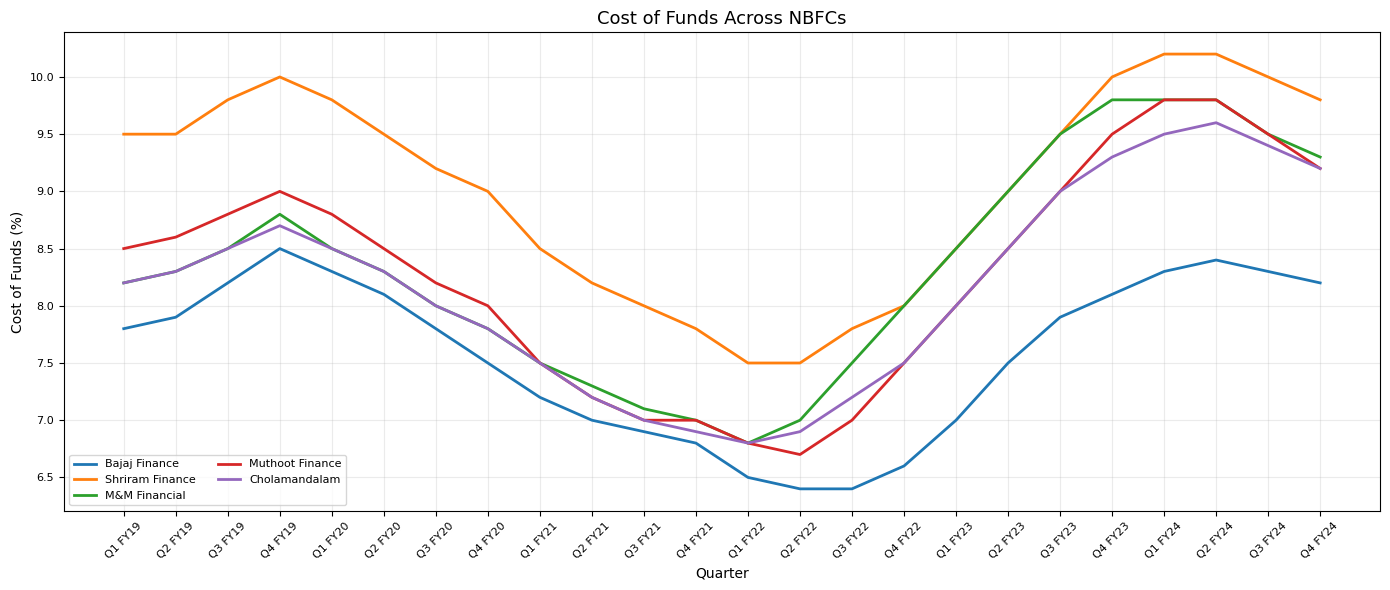

In [ ]:
plt.figure(figsize=(14,6))

companies = df["Company"].unique()

for company in companies:

    temp = df[df["Company"] == company]

    plt.plot(
        temp["Quarter"],
        temp["CoF (%)"],
        linewidth=2,
        label=company
    )

plt.title(
    "Cost of Funds Across NBFCs",
    fontsize=13
)

plt.xlabel("Quarter", fontsize=10)

plt.ylabel("Cost of Funds (%)", fontsize=10)

plt.xticks(rotation=45, fontsize=8)

plt.yticks(fontsize=8)

plt.legend(
    fontsize=8,
    ncol=2
)

plt.grid(alpha=0.25)

plt.tight_layout()

plt.show()


**Interpretation**

Expected observations:

•	retail NBFCs react faster,

•	housing finance firms react slower,

•	market-dependent NBFCs exhibit higher volatility.

**RBI Repo Rate vs Loan Growth**

**Purpose**

Tests whether repo hikes reduce NBFC credit expansion.


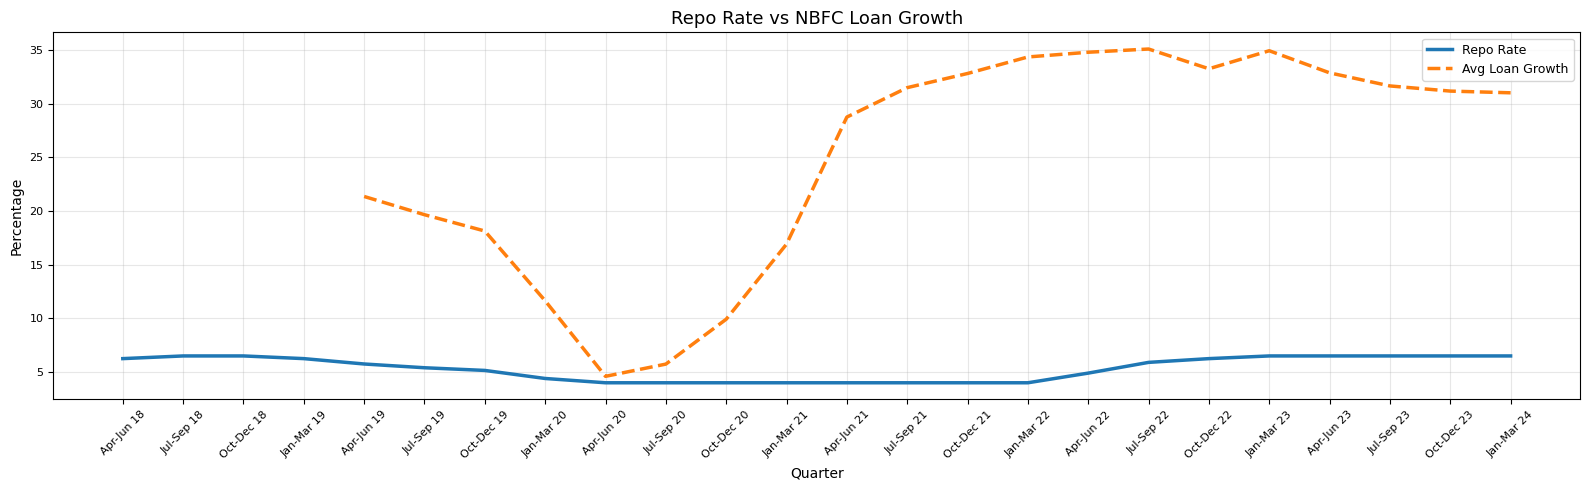

In [ ]:
quarterly = df.groupby(
    ["Date", "Calendar Period"]
).agg({
    "Repo Rate (%)":"mean",
    "Loan Growth YoY%":"mean"
}).reset_index()

quarterly = quarterly.sort_values("Date")

plt.figure(figsize=(16,5))

plt.plot(
    quarterly["Calendar Period"],
    quarterly["Repo Rate (%)"],
    linewidth=2.5,
    label="Repo Rate"
)

plt.plot(
    quarterly["Calendar Period"],
    quarterly["Loan Growth YoY%"],
    linewidth=2.5,
    linestyle="--",
    label="Avg Loan Growth"
)

plt.title(
    "Repo Rate vs NBFC Loan Growth",
    fontsize=13
)

plt.xlabel(
    "Quarter",
    fontsize=10
)

plt.ylabel(
    "Percentage",
    fontsize=10
)

plt.xticks(
    rotation=45,
    fontsize=8
)

plt.yticks(
    fontsize=8
)

plt.legend(
    fontsize=9
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

**Interpretation**

Expected finding:

•	higher repo rates associated with slower lending growth,

•	effect likely lagged by 1–2 quarters.

**Loan Growth During Hikes vs Cuts**

**Purpose**

Tests asymmetry in monetary transmission.

In [ ]:
conditions = []

for x in df["Repo QoQ Chg (bps)"]:

    if x > 0:
        conditions.append("Hike")

    elif x < 0:
        conditions.append("Cut")

    else:
        conditions.append("No Change")

df["Policy Phase"] = conditions


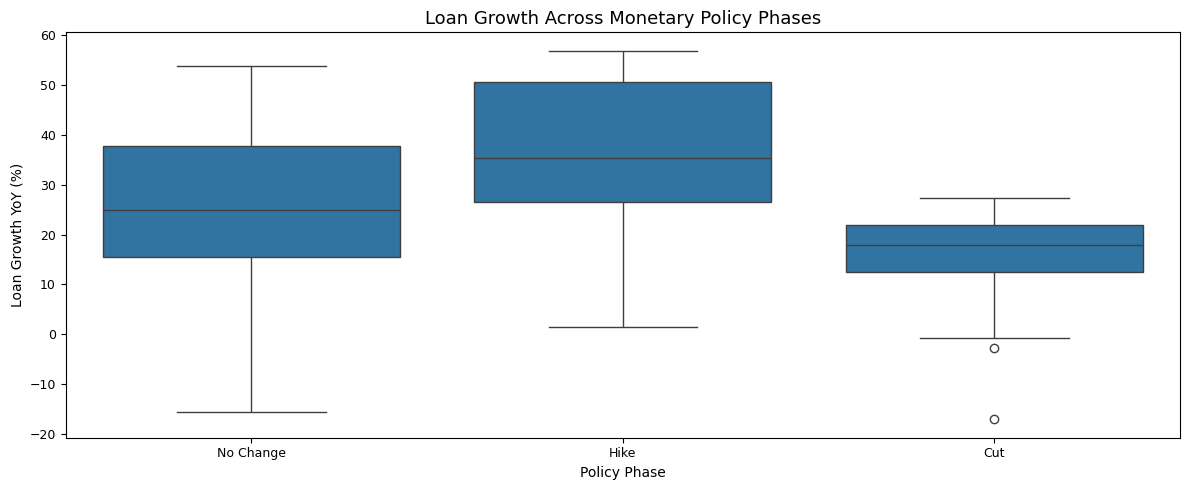

In [ ]:
sns.boxplot(
    data=df,
    x="Policy Phase",
    y="Loan Growth YoY%"
)

plt.title(
    "Loan Growth Across Monetary Policy Phases",
    fontsize=13
)

plt.xlabel("Policy Phase", fontsize=10)

plt.ylabel("Loan Growth YoY (%)", fontsize=10)

plt.xticks(fontsize=9)

plt.yticks(fontsize=9)

plt.tight_layout()

plt.show()


**Interpretation**

Expected observation:

•	rate hikes suppress lending sharply,

•	rate cuts stimulate lending weakly.

This supports: “Rocket and Feathers” transmission asymmetry.


**Correlation Matrix**

**Purpose**

Shows preliminary relationships between variables.

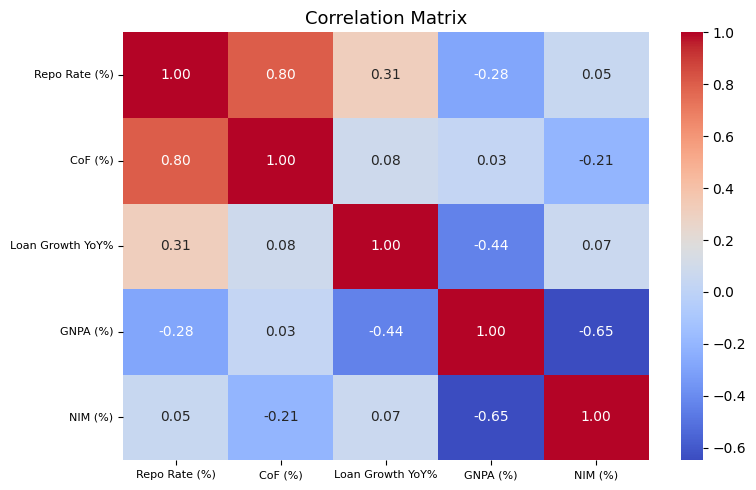

In [ ]:
corr = df[[
    "Repo Rate (%)",
    "CoF (%)",
    "Loan Growth YoY%",
    "GNPA (%)",
    "NIM (%)"
]].corr()

plt.figure(figsize=(8,5))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title(
    "Correlation Matrix",
    fontsize=13
)

plt.xticks(fontsize=8)

plt.yticks(fontsize=8)

plt.tight_layout()

plt.show()


**DESCRIPTIVE STATISTICS**

**Purpose**

Summarizes:

•	average values,

•	volatility,

•	minimum and maximum ranges.

In [ ]:
desc = df[[
    "Repo Rate (%)",
    "CoF (%)",
    "Loan Growth YoY%",
    "GNPA (%)",
    "NIM (%)"
]].describe()

print(desc)

       Repo Rate (%)     CoF (%)  Loan Growth YoY%    GNPA (%)     NIM (%)
count     120.000000  120.000000        100.000000  120.000000  120.000000
mean        5.322917    8.270000         25.013000    4.907500    9.440833
std         1.081935    1.000722         16.836376    3.043637    1.903314
min         4.000000    6.400000        -17.100000    0.900000    6.800000
25%         4.000000    7.500000         14.975000    2.725000    7.800000
50%         5.575000    8.250000         23.250000    3.950000    8.650000
75%         6.500000    9.000000         36.950000    7.200000   11.000000
max         6.500000   10.200000         56.900000   16.000000   13.200000


**Expected Insights**

•	Loan growth more volatile than repo rates.

•	GNPA spikes during stress periods.

•	CoF variability reflects market-linked funding.


In [ ]:
df = pd.read_csv("/content/Untitled spreadsheet - master sheet (1).csv")

df.head()

,Company,Ticker,Quarter,Calendar Period,Repo Rate (%),Repo QoQ Chg (bps),Rate Hike,Rate Cut,AUM (Cr),Loan Growth YoY%,GNPA (%),NIM (%),CoF (%),Spread (%),CAR (%),GDP Growth YoY %,CPI Inflation%,IL&FS Dummy,COVID Dummy
0,Bajaj Finance,BAJFINANCE,Q1 FY19,Apr-Jun 18,6.25,NaN,NaN,NaN,"97,000",NaN,1.6,10.8,7.8,3.0,22.5,8.0,4.92,0,0
1,Bajaj Finance,BAJFINANCE,Q2 FY19,Jul-Sep 18,6.50,25.0,25.0,0.0,"1,05,000",NaN,1.5,10.9,7.9,3.0,22.2,7.0,3.70,1,0
2,Bajaj Finance,BAJFINANCE,Q3 FY19,Oct-Dec 18,6.50,0.0,0.0,0.0,"1,10,700",NaN,1.6,11.0,8.2,2.8,22.0,6.6,2.33,1,0
3,Bajaj Finance,BAJFINANCE,Q4 FY19,Jan-Mar 19,6.25,-25.0,0.0,25.0,"1,15,888",NaN,1.5,10.9,8.5,2.4,21.8,5.8,2.57,0,0
4,Bajaj Finance,BAJFINANCE,Q1 FY20,Apr-Jun 19,5.75,-50.0,0.0,50.0,"1,23,000",26.8,1.6,10.7,8.3,2.4,22.0,5.2,3.18,0,0


**BASELINE REGRESSION**

**Model Specification**

LoanGrowth_t = α + β₁RepoRate_t + β₂GDP_t + β₃CPI_t + ε_t
________________________________________
***Purpose***

Tests whether repo rate changes significantly affect NBFC lending growth


In [ ]:
import statsmodels.api as sm

X = df[[
    "Repo Rate (%)",
    "GDP Growth YoY %",
    "CPI Inflation%"
]]

Y = df["Loan Growth YoY%"]

X = sm.add_constant(X)

model = sm.OLS(Y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       Loan Growth YoY%   R-squared:                         nan
Model:                            OLS   Adj. R-squared:                    nan
Method:                 Least Squares   F-statistic:                       nan
Date:                Wed, 10 Jun 2026   Prob (F-statistic):                nan
Time:                        01:17:23   Log-Likelihood:                    nan
No. Observations:                 120   AIC:                               nan
Df Residuals:                     116   BIC:                               nan
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                   nan        nan  

**LAG ANALYSIS**

**Model Specification **

LoanGrowth_t = α + β₁RepoRate_(t−1) + Controls + ε_t
________________________________________
**Purpose**

Tests delayed transmission effects.


In [ ]:
df["Repo_Lag1"] = df["Repo Rate (%)"].shift(1)

df["Repo_Lag2"] = df["Repo Rate (%)"].shift(2)


In [ ]:
X = df[[
     "Repo Rate (%)",
     "GDP Growth YoY %",
     "CPI Inflation%"
]]

Y = df["Loan Growth YoY%"]

X = sm.add_constant(X)

lag_model = sm.OLS(
    Y,
    X,
    missing='drop'
).fit()

print(lag_model.summary())


                            OLS Regression Results                            
Dep. Variable:       Loan Growth YoY%   R-squared:                       0.228
Model:                            OLS   Adj. R-squared:                  0.204
Method:                 Least Squares   F-statistic:                     9.463
Date:                Wed, 10 Jun 2026   Prob (F-statistic):           1.55e-05
Time:                        01:19:14   Log-Likelihood:                -410.79
No. Observations:                 100   AIC:                             829.6
Df Residuals:                      96   BIC:                             840.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                2.2128     11.939  

**Expected Findings**

•	Lagged repo variable stronger than current repo rate.

•	Monetary transmission occurs after 1–2 quarters.

**ASYMMETRY ANALYSIS**

**Model Specification**

LoanGrowth_t = α + β₁RateHike_t + β₂RateCut_t + Controls + ε_t
________________________________________
**Purpose**

Tests whether repo hikes affect lending more strongly than repo cuts.

In [ ]:
df["Rate_Hike"] = df["Repo QoQ Chg (bps)"].apply(
    lambda x: x if x > 0 else 0
)

df["Rate_Cut"] = df["Repo QoQ Chg (bps)"].apply(
    lambda x: abs(x) if x < 0 else 0
)

In [ ]:
X = df[[
    "Rate_Hike",
    "Rate_Cut",
    "GDP Growth YoY %",
    "CPI Inflation%"
]]

Y = df["Loan Growth YoY%"]

X = sm.add_constant(X)

asym_model = sm.OLS(Y, X).fit()

print(asym_model.summary())

                            OLS Regression Results                            
Dep. Variable:       Loan Growth YoY%   R-squared:                         nan
Model:                            OLS   Adj. R-squared:                    nan
Method:                 Least Squares   F-statistic:                       nan
Date:                Wed, 10 Jun 2026   Prob (F-statistic):                nan
Time:                        01:21:59   Log-Likelihood:                    nan
No. Observations:                 120   AIC:                               nan
Df Residuals:                     115   BIC:                               nan
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                   nan        nan  